In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, r2_score , mean_absolute_error
import joblib

In [2]:
x_train = pd.read_csv('../data/processed/x_train_scaled.csv')
y_train = pd.read_csv('../data/processed/y_train.csv')
x_val = pd.read_csv('../data/processed/x_val_scaled.csv')
y_val = pd.read_csv('../data/processed/y_val.csv')
x_test = pd.read_csv('../data/processed/x_test_scaled.csv')
y_test = pd.read_csv('../data/processed/y_test.csv')

In [3]:
XGB_model = XGBRegressor(objective='reg:squarederror', n_estimators=100, learning_rate=0.1, max_depth=3)
XGB_model.fit(x_train, y_train)
y_pred = XGB_model.predict(x_test)
y_pred = pd.DataFrame(y_pred, columns=['RUL'])


In [4]:
print("Mean Squared Error:", mean_squared_error(y_test, y_pred))
print("R-squared:", r2_score(y_test, y_pred))
print("Mean Absolute Error:", mean_absolute_error(y_test, y_pred))

Mean Squared Error: 5911.263199456422
R-squared: -1.0999831544632808
Mean Absolute Error: 64.97561974920875


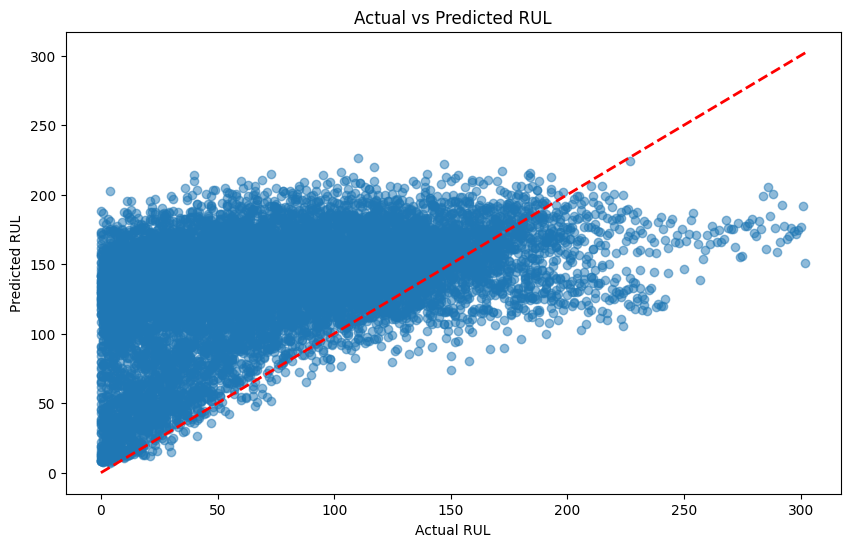

In [5]:
plt.figure(figsize=(10, 6))
plt.scatter(y_test, y_pred, alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel('Actual RUL')
plt.ylabel('Predicted RUL')
plt.title('Actual vs Predicted RUL')    
plt.show()

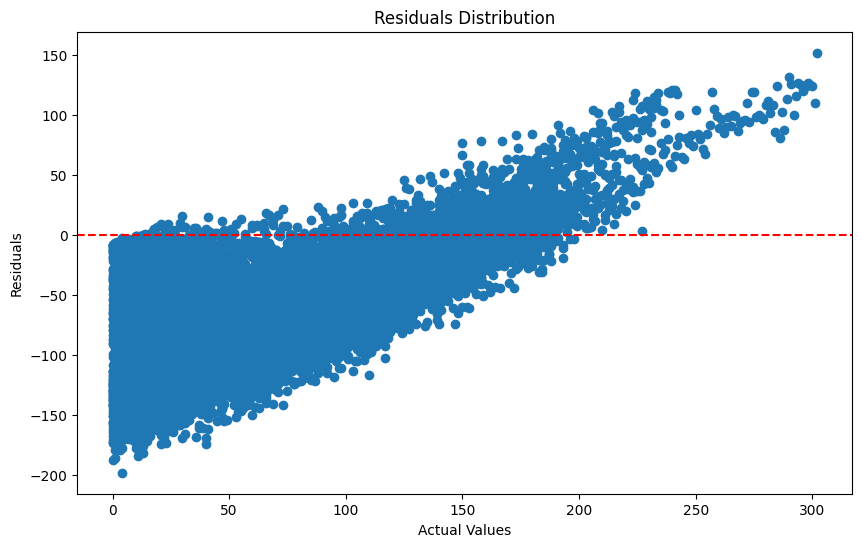

In [6]:
#plotting the residuals
residuals = y_test - y_pred
plt.figure(figsize=(10, 6))
plt.scatter(x=y_test, y=residuals)
plt.axhline(y=0, color='r', linestyle='--')
plt.title('Residuals Distribution')
plt.xlabel('Actual Values')
plt.ylabel('Residuals')     
plt.show()

In [7]:
# save the model
joblib.dump(XGB_model, '../models/xgb_model.pkl')

['../models/xgb_model.pkl']